# EEG-DINO v2: общий набор, новые случайные окна на каждой эпохе, веса сохраняются (Г1)

| Поле | Значение |
|------|----------|
| **Автор** | Захар Санников (zs) |
| **Дата** | 2026-11-02 |
| **Гипотеза** | Г1 (ЭЭГ) |
| **Цель** | Повторить дообучение EEG-DINO-M (блокнот 22.10, ядра `h1-eegdino-finetune`, `h1-eegdino-seed2`) с сохранением весов, чтобы проверить её на третьей больнице EpiEEG-60 и собрать ансамбль с REVE v4 к выбору моделей 08.11 |
| **Что изменено против 22.10** | (1) данные — общий набор `zakharsann/h1-prep-shared` (`shared_data.py`): 200 Гц, 0,1–75 Гц + 50 Гц, мкВ, + ФВЧ 0,3 Гц по записи целиком (как REVE v4; 22.10 — 0,3–75 Гц по записи); деление fit / val то же; (2) на каждой эпохе каждое окно обучения — **новое случайное окно** своей записи, как в REVE v4 (22.10 — одни и те же 8 окон на запись); записи выбираются с уравниванием классов; окон за эпоху 8 × (записей fit); (3) веса всех запусков — в выход ядра; (4) кривые обучения: потери на обучении, потери и ROC AUC на отложенных 15 % по эпохам |
| **Без изменений** | EEG-DINO-M (HF `eegdino/EEG-DINO`, снимок `5d8ae132`, студент, строгая загрузка), голова авторов на 1 выход, окно 10 с → 19 × 10 патчей по 1 с, окно к общему СКО 15 мкВ, /100, обрезка ±5; аугментации (шум 0,1·СКО, замена полушарий, зануление 1–2 каналов, сдвиг до 2 с); полное дообучение, AdamW (wd 0,05, без wd для смещений и норм), послойное снижение 0,9, разогрев 10 % + косинус на 10 эпох, пакет 64, fp16; **скорость 5·10⁻⁴** (выбрана 22.10, повторно не подбиралась); до 10 эпох, остановка, если ROC AUC отложенных не растёт 2 эпохи; берётся лучшая эпоха; 3 запуска (seed 0, 1, 2) |
| **Выбор эпохи** | отложенные 15 % NMT train (335 записей), 12 окон на запись равномерно, медиана (как REVE v4) |
| **Оценка** | NMT eval (185), Турция (121), EpiEEG-60 (63 человека; выход `zakharsann/h1-epieeg60-prep`). Окна 10 с подряд с начала записи; основной вид — 60 окон равномерно, **оценка записи — среднее верхних 20 % окон**, ансамбль 3 запусков — среднее вероятностей. Дополнительно — все окна и медиана |
| **Сравнение** | старая EEG-DINO (22.10; есть только медиана 60 окон и только NMT eval / Турция — веса не сохранялись, на EpiEEG-60 её нет); REVE v4 (`reve_v4_per_person.csv`, `epieeg60_per_person.csv` — выходы ядер `h1-reve-v4`, `h1-epieeg60-reve`); ансамбль REVE v4 + EEG-DINO v2 — среднее вероятностей. Парные разности ROC AUC — бутстреп по людям (2000) |
| **Порог** | Юден и чувствительность 80 % по отложенным 15 % NMT train, на остальные наборы переносится без изменений. Калибровка на месте (Турция, EpiEEG-60): порог по k = 10 / 20 случайным людям, метрики на остальных, 500 повторов, одни и те же выборки для всех моделей (как `ensemble_recall80.py`) |
| **Бюджет** | ≤ 2,5 ч T4 вместе с короткой проверкой (она на процессоре) |

**Веса в выходе блокнота** (в git не кладутся): `eegdino_v2_seed0.pt`, `eegdino_v2_seed1.pt`, `eegdino_v2_seed2.pt` — `torch.save({"state_dict": ..., "config": ...})`.
- `state_dict` — веса всей модели `DinoNet` (fp32): `encoder.*` — кодировщик EEG-DINO-M, `full_linear.*`, `channel_linear.*`, `classifier.*` — голова авторов из `run_finetuning.py` на 1 выход.
- `config` — каналы и порядок, подготовка входа, параметры обучения, лучшая эпоха, ROC AUC отложенных.
- Вход: 19 каналов в порядке Fp1 Fp2 F3 F4 C3 C4 P3 P4 O1 O2 F7 F8 T3 T4 T5 T6 Fz Cz Pz (номер канала = номер one-hot вложения, порядок важен), средний референт, 200 Гц, 0,1–75 Гц + режекция 50 Гц + ФВЧ 0,3 Гц по записи целиком, окно 10 с (2000 отсчётов); из каждого канала вычитается его среднее, окно приводится к общему СКО 15 мкВ и делится на 100, обрезка ±5. Выход — логит, вероятность = sigmoid.
- Загрузка: класс `DinoNet` и функция `dino_input` — в файле `eegdino_v2_model.py` выхода; `m = DinoNet(); m.load_state_dict(torch.load(path)["state_dict"])`. Код слоёв авторов берётся с HF на том же снимке (без интернета — `DinoNet(src_dir=...)`).

## Итоги (02.11.2026)

**ROC AUC (95 % ДИ, бутстреп по людям); оценка записи — среднее верхних 20 % из 60 окон, ансамбль 3 запусков:**

| модель | отложенные 15 % | NMT eval | Турция | EpiEEG-60 |
|---|---|---|---|---|
| EEG-DINO v2 | 0,912 (0,88–0,95) | 0,901 (0,85–0,94) | 0,858 (0,78–0,92) | 0,748 (0,62–0,87) |
| EEG-DINO 22.10 (медиана окон) | 0,893 | 0,876 | 0,892 | нет |
| REVE v4 | 0,906 | 0,913 | 0,923 | 0,761 |
| REVE v4 + EEG-DINO v2 | 0,922 | 0,920 | 0,936 | 0,756 |

- **v2 против старой EEG-DINO.** На NMT eval +0,024 (+0,003…+0,049), но весь прирост дала другая сборка оценки (верхние 20 % вместо медианы). При одинаковой сборке (медиана 60 окон) разница −0,003 на NMT eval и **−0,046 (−0,090…−0,009) на Турции**. Новые случайные окна и общий набор переносимость на Турцию не улучшили.
- **Запуски сильно расходятся на Турции:** 0,85 / 0,78 / 0,90 (seed 0/1/2). На NMT eval разброс маленький: 0,89 / 0,90 / 0,90.
- **Ансамбль с REVE v4.** Разница с REVE v4: +0,007 на NMT eval, +0,013 на Турции, −0,005 на EpiEEG-60; на всех трёх наборах ДИ включает 0. Против ансамбля REVE + старая EEG-DINO: +0,017 (+0,002…+0,035) на NMT eval, на Турции 0.
- **EpiEEG-60.** У больных с размеченными разрядами 0,792, без разрядов 0,598 (7 человек, ДИ 0,32–0,86). Тот же характер, что у REVE v4 (0,807 / 0,603).
- **Порог с отложенных 15 %** (Юден, 0,786) на NMT eval даёт чувствительность 0,83 и специфичность 0,83. На Турции и EpiEEG-60 этот порог не переносится: чувствительность 0,00 и 0,29. Калибровка порога на 20 людях: на Турции сбалансированная accuracy у ансамбля 0,84, у REVE v4 0,81; на EpiEEG-60 у обоих 0,69.
- **Кривые обучения.** Потери на обучении падают ровно. Потери на отложенных по всем окнам сильно скачут, потому что больных там мало. Потери с уравниванием классов снижаются с 0,69 до ~0,51 и к концу выходят на плато. ROC AUC растёт до эпох 6–10. Seed 2 дошёл до 10 эпох без остановки, так что, возможно, недообучен. Явного переобучения нет.
- **Затраты:** одно ядро T4, 79 мин (обучение 71,5 мин, ~2,2 мин на эпоху), квота GPU — 1,33 ч. Проверка на CPU — 16 мин.


In [ ]:
MODEL_SRC = r'''"""EEG-DINO v2 (Г1): модель и подготовка окна. Веса — eegdino_v2_seed{0,1,2}.pt выхода блокнота zakharsann/h1-eegdino-v2.

    import torch
    from eegdino_v2_model import DinoNet, dino_input
    ck = torch.load("eegdino_v2_seed0.pt", map_location="cpu")
    m = DinoNet(); m.load_state_dict(ck["state_dict"]); m.eval()
    p = torch.sigmoid(m(dino_input(W)))      # W: (окна, 19, 2000), мкВ, 200 Гц, каналы в порядке EL

Вложение патчей и слой трансформера — файлы авторов models/embedding_medium.py и models/transformer.py
из HF eegdino/EEG-DINO на зафиксированном снимке; без интернета — DinoNet(src_dir=папка, где лежит models/).
"""
import os, sys, types, numpy as np, torch, torch.nn as nn, torch.nn.functional as F

HF_REPO, HF_REV = "eegdino/EEG-DINO", "5d8ae13252a4170789140b10e3e91fd32f603155"   # снимок репозитория авторов, проверен 21.10.2026
EL = ["Fp1", "Fp2", "F3", "F4", "C3", "C4", "P3", "P4", "O1", "O2", "F7", "F8", "T3", "T4", "T5", "T6", "Fz", "Cz", "Pz"]
D_MODEL, N_LAYERS, D_FF = 512, 16, 1024           # EEG-DINO-M
N_HEADS, N_GLOBAL, GLOBAL_LAYER = 8, 1, 1          # значения по умолчанию run_finetuning.py (число голов в статье не указано)
SFREQ, SEG, PATCH, STD_UV = 200, 10, 200, 15.0
_MODS = {}


def author_file(f, src_dir=None, cache_dir=None):
    """Файл репозитория авторов: из локальной папки или с HF (зафиксированный снимок)."""
    if src_dir:
        return os.path.join(src_dir, f)
    from huggingface_hub import hf_hub_download
    return hf_hub_download(HF_REPO, f, revision=HF_REV, cache_dir=cache_dir)


def _load_src(name, path, fixes=()):
    """Модуль авторов из файла с точечными правками (каждая правка должна найтись ровно один раз)."""
    src = open(path, encoding="utf-8").read()
    for a, b in fixes:
        assert src.count(a) == 1, (name, a)
        src = src.replace(a, b)
    mod = types.ModuleType(name); sys.modules[name] = mod
    exec(compile(src, path, "exec"), mod.__dict__)
    return mod


def author_modules(src_dir=None, cache_dir=None):
    """Вложение патчей и слой трансформера авторов. .cuda() зашит в их код — заменён на устройство входа; БПФ длины 200 в fp16 не работает — вложение в fp32."""
    if not _MODS:
        emb = _load_src("dino_embedding", author_file("models/embedding_medium.py", src_dir, cache_dir),
                        [("torch.arange(self.num_channels+1).cuda()", "torch.arange(self.num_channels+1, device=x.device)")])
        trf = _load_src("dino_transformer", author_file("models/transformer.py", src_dir, cache_dir))
        fwd = emb.PatchEmbedding.forward
        def fwd32(self, x):
            with torch.autocast("cuda", enabled=False):
                return fwd(self, x.float())
        emb.PatchEmbedding.forward = fwd32
        _MODS.update(emb=emb, trf=trf)
    return _MODS["emb"], _MODS["trf"]


def dino_input(W):
    """Окно (B, 19, 2000), мкВ -> из каждого канала вычесть среднее, окно к общему СКО 15 мкВ (по всем каналам и отсчётам), /100 как у авторов, обрезка ±5."""
    x = torch.as_tensor(np.asarray(W, np.float32))
    x = x - x.mean(-1, keepdim=True)
    return (x / (x.std(dim=(1, 2), keepdim=True) + 1e-6) * (STD_UV / 100.0)).clamp(-5, 5)


class EEGEncoder(nn.Module):
    """Как models/eeg_encoder.py авторов (там лишний импорт monai и жёстко embedding_small)."""
    def __init__(self, emb, trf):
        super().__init__()
        self.patch_embedding = emb.PatchEmbedding(d_model=D_MODEL)
        self.encoder_layers = nn.ModuleList([trf.TransformerEncoderLayer(d_model=D_MODEL, nhead=N_HEADS, dim_feedforward=D_FF) for _ in range(N_LAYERS)])
        self.global_tokens = nn.Parameter(torch.randn(1, N_GLOBAL, D_MODEL))

    def forward(self, x_in):
        x = self.patch_embedding(x_in)            # [B, C, P, D]
        b = x.shape[0]
        x = x.reshape(b, -1, x.shape[-1])         # [B, C*P, D]
        g = self.global_tokens.expand(b, -1, -1)
        for i, layer in enumerate(self.encoder_layers):
            x = layer(x)
            if i + 1 == GLOBAL_LAYER:
                x = torch.cat([g, x], dim=1)
        return x


class DinoNet(nn.Module):
    """Кодировщик EEG-DINO-M + голова ClassificationModel из run_finetuning.py (среднее по каналам, затем по времени, MLP) на 1 выход."""
    def __init__(self, src_dir=None, cache_dir=None):
        super().__init__()
        emb, trf = author_modules(src_dir, cache_dir)
        d = D_MODEL
        self.encoder = EEGEncoder(emb, trf)
        self.full_linear, self.channel_linear = nn.Linear(d, d), nn.Linear(d, d)
        self.classifier = nn.Sequential(nn.Linear(d, d // 2), nn.GELU(), nn.Dropout(0.5),
                                        nn.Linear(d // 2, d // 4), nn.GELU(), nn.Dropout(0.3), nn.Linear(d // 4, 1))

    def forward(self, x):
        if x.dim() == 3:                          # (B, 19, 2000) -> (B, 19, 10, 200)
            x = x.reshape(x.shape[0], x.shape[1], -1, PATCH)
        bs, ch, P, _ = x.shape
        f = self.encoder(x)[:, N_GLOBAL:]
        f = F.gelu(self.full_linear(f)).reshape(bs, ch, P, -1).mean(1)   # [bs, P, d]
        f = F.gelu(self.channel_linear(f)).mean(1)                       # [bs, d]
        return self.classifier(f).squeeze(-1)
'''

In [ ]:
"""Общий набор Г1 (NMT + турецкий) — выход блокнота Kaggle zakharsann/h1-prep-shared.

Подключение в kernel-metadata.json: "kernel_sources": ["zakharsann/h1-prep-shared"].
Блокноты моделей копируют этот файл в начало (одна ячейка) и пользуются функциями ниже.

Формат (подробно — в описании блокнота h1_2026-10-26_zs_prep-shared.ipynb):
- h1_shared_meta.csv — по строке на запись: dataset, part, split, id, y, ..., shard200/off200/n200 (и shard256/... если есть);
- h1_shared_info.json — фильтр, множитель масштаба NMT, сколько минут NMT train сохранено, порядок каналов;
- fs200/<имя>.npy — плоские массивы float16: записи (19, n) в C-порядке подряд, запись = arr[off : off + 19*n].
Сигнал в мкВ, 19 каналов в порядке EL, средний референт, 0,1-75 Гц + режекция 50 Гц. Окна НЕ нормированы.
"""
import glob, json, os
from fractions import Fraction
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, scipy.signal as ss

EL = ["Fp1", "Fp2", "F3", "F4", "C3", "C4", "P3", "P4", "O1", "O2", "F7", "F8", "T3", "T4", "T5", "T6", "Fz", "Cz", "Pz"]


def find_root(base="/kaggle/input"):
    """Папка общего набора среди подключённых источников."""
    hits = glob.glob(f"{base}/**/h1_shared_meta.csv", recursive=True)
    assert hits, "общий набор не подключён: добавьте zakharsann/h1-prep-shared в kernel_sources"
    return os.path.dirname(hits[0])


def load_meta(root):
    """Таблица записей и описание набора."""
    meta = pd.read_csv(f"{root}/h1_shared_meta.csv")
    info = json.load(open(f"{root}/h1_shared_info.json", encoding="utf-8"))
    return meta, info


_SHARDS = {}
def _shard(root, fs, name):
    k = (root, fs, name)
    if k not in _SHARDS:
        _SHARDS[k] = np.load(f"{root}/fs{fs}/{name}", mmap_mode="r")
    return _SHARDS[k]


def read_record(root, row, fs=200):
    """Одна запись: (19, n) float16, мкВ. row — строка meta (Series или dict).
    Через mmap — для единичных записей; много записей читать через read_all (на /kaggle/input mmap очень медленный)."""
    n, off = int(row[f"n{fs}"]), int(row[f"off{fs}"])
    return np.array(_shard(root, fs, row[f"shard{fs}"])[off:off + 19 * n]).reshape(19, n)


def read_all(root, meta, fs=200, threads=4):
    """Все записи meta в словарь id -> (19, n) float16: каждый файл-кусок читается целиком последовательно, записи режутся в памяти."""
    def load(item):
        name, g = item
        arr = np.load(f"{root}/fs{fs}/{name}")
        return [(i, arr[o:o + 19 * n].reshape(19, n).copy()) for i, o, n in zip(g["id"], g[f"off{fs}"], g[f"n{fs}"])]
    out = {}
    with ThreadPoolExecutor(threads) as ex:
        for part in ex.map(load, list(meta.groupby(f"shard{fs}"))):
            out.update(part)
    return {i: out[i] for i in meta["id"]}


def windows(X, L, S=None):
    """Окна длиной L с шагом S (по умолчанию S = L, подряд): (k, 19, L)."""
    S = S or L
    k = (X.shape[-1] - L) // S + 1 if X.shape[-1] >= L else 0
    if k <= 0:
        return np.zeros((0,) + X.shape[:-1] + (L,), X.dtype)
    return np.lib.stride_tricks.sliding_window_view(X, L, axis=-1)[..., ::S, :][..., :k, :].swapaxes(0, -2).copy()


def random_windows(X, L, K, rng):
    """K окон длиной L со случайным началом (любой отсчёт) — свежие окна на каждой эпохе: (K, 19, L)."""
    n = X.shape[-1] - L + 1
    if n <= 0:
        return np.zeros((0,) + X.shape[:-1] + (L,), X.dtype)
    st = np.sort(rng.integers(0, n, K))
    return np.stack([X[..., s:s + L] for s in st])


def resample(X, fs_from, fs_to):
    """Пересчёт частоты (полифазный, как scipy.signal.resample_poly) по последней оси, float32 на выходе."""
    if fs_from == fs_to:
        return X
    fr = Fraction(int(fs_to), int(fs_from))
    return ss.resample_poly(np.asarray(X, np.float32), fr.numerator, fr.denominator, axis=-1).astype(np.float32)


def highpass(X, f, fs=200, order=4):
    """Дофильтровка сверху общей нижней границы 0,1 Гц (например, 0,3 Гц как у CBraMod): по всей записи, не по окну."""
    sos = ss.butter(order, f, btype="highpass", fs=fs, output="sos")
    return ss.sosfiltfilt(sos, np.asarray(X, np.float64), axis=-1).astype(np.float32)

In [ ]:
import os, glob, time, json, io, warnings
SMOKE = False   # True — короткая проверка на процессоре Kaggle (часть записей, 1 эпоха); её метрики не смотреть
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import roc_auc_score, roc_curve
from concurrent.futures import ThreadPoolExecutor
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
from PIL import Image
DEV = "cuda" if torch.cuda.is_available() else "cpu"
OUT = "/kaggle/working"; FIG = f"{OUT}/figures"; os.makedirs(FIG, exist_ok=True)
T_NB = time.time()
END = T_NB + (60 if SMOKE else 130) * 60      # весь блокнот — не дольше 130 мин T4
left = lambda: (END - time.time()) / 60

SFREQ, SEG = 200, 10
L = SFREQ * SEG
K_TRAIN, N_VAL_EP, CAP_EVAL, HP = 8, 12, 60, 0.3
SEEDS = [0, 1, 2]
CACHE = "/kaggle/temp/hf"                     # не в /kaggle/working: предобученные веса не попадают в выход

# модель и подготовка окна — один источник, он же сохраняется в выход как eegdino_v2_model.py
open(f"{OUT}/eegdino_v2_model.py", "w", encoding="utf-8").write(MODEL_SRC)
exec(compile(MODEL_SRC, "eegdino_v2_model.py", "exec"))
author_modules(cache_dir=CACHE)
CK = torch.load(author_file("pre-trained-models/model_EEG_DINO_M.pt", cache_dir=CACHE), map_location="cpu", weights_only=True)["state_dict"]
STUDENT = {k[len("module.student."):]: v for k, v in CK.items() if k.startswith("module.student.")}
del CK

def new_dino(seed):
    torch.manual_seed(seed)
    m = DinoNet()
    m.encoder.load_state_dict(STUDENT, strict=True)   # строго: ни одного пропущенного или лишнего ключа кодировщика
    return m.to(DEV)

_m = new_dino(0)
print(f"EEG-DINO-M: кодировщик {len(STUDENT)} тензоров загружено строго; параметров {sum(p.numel() for p in _m.parameters())}")
del _m

MIRROR_PAIRS = {"Fp1": "Fp2", "F3": "F4", "C3": "C4", "P3": "P4", "O1": "O2", "F7": "F8", "T3": "T4", "T5": "T6"}
MIRROR_PAIRS.update({v: k for k, v in list(MIRROR_PAIRS.items())})
MIRROR = [EL.index(MIRROR_PAIRS.get(e, e)) for e in EL]
AMP = dict(device_type="cuda", dtype=torch.float16, enabled=DEV == "cuda")

def predict_logits(model, Ws, bs=256):
    """Логит каждого окна: список массивов, по одному на запись."""
    model.eval(); out = []
    with torch.no_grad(), torch.autocast(**AMP):
        for W in Ws:
            p = [model(dino_input(W[b:b + bs]).to(DEV)).float().cpu().numpy() for b in range(0, len(W), bs)]
            out.append(np.concatenate(p) if p else np.zeros(0, np.float32))
    return out
sigm = lambda z: 1 / (1 + np.exp(-z))

def boot_ci(yt, s, n=2000, seed=0):
    r = np.random.default_rng(seed); v = []
    for _ in range(n):
        i = r.integers(0, len(yt), len(yt))
        if len(set(yt[i])) == 2: v.append(roc_auc_score(yt[i], s[i]))
    return np.percentile(v, [2.5, 97.5])

def spread(n, k):
    return np.unique(np.linspace(0, n - 1, k).astype(int)) if n > k else np.arange(n)

plt.rcParams.update({"font.size": 10, "axes.titlesize": 10, "figure.dpi": 100})
def save_png(fig, name, limit=290_000):
    path = f"{FIG}/{name}"
    for dpi in [100, 85, 70, 60]:
        buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight"); buf.seek(0)
        img = Image.open(buf)
        if buf.getbuffer().nbytes > limit:
            img = img.convert("RGB").quantize(256)
        img.save(path, optimize=True)
        if os.path.getsize(path) <= limit:
            break
    plt.close(fig)
print("устройство:", torch.cuda.get_device_name(0) if DEV == "cuda" else "процессор", "| ядер процессора:", os.cpu_count())

## 2. Данные: общий набор (NMT + Турция) и EpiEEG-60, ФВЧ 0,3 Гц по записи, окна для выбора эпохи

In [ ]:
ROOT = find_root()
meta, info = load_meta(ROOT)
print("общий набор:", ROOT, {k: info.get(k) for k in ["fs", "nmt_scale_k", "nmt_train_cap_min", "size_gb"]})
need = meta[meta.split.isin(["fit", "val", "eval", "turkey"])].copy()
if SMOKE:
    pick = lambda s, n0, n1: pd.concat([need[(need.split == s) & (need.y == 0)].head(n0), need[(need.split == s) & (need.y == 1)].head(n1)])
    need = pd.concat([pick("fit", 24, 12), pick("val", 6, 4), pick("eval", 5, 5), pick("turkey", 8, 8)])
t0 = time.time()
REC = read_all(ROOT, need)
t_read = time.time() - t0

# EpiEEG-60: подготовка как в общем наборе (выход zakharsann/h1-epieeg60-prep), по одной записи на человека
PREP = os.path.dirname(glob.glob("/kaggle/input/**/epieeg60_records.csv", recursive=True)[0])
ER = pd.read_csv(f"{PREP}/epieeg60_records.csv")
ER = ER[ER.n200.notna()].sort_values(["person", "id"]).reset_index(drop=True)
if SMOKE:
    ER = pd.concat([ER[ER.y == 0].head(8), ER[ER.y == 1].head(8)]).sort_values(["person", "id"]).reset_index(drop=True)
for r in ER.itertuples():
    REC[f"epi:{r.id}"] = np.load(f"{PREP}/fs200/{r.id}.npy")

def hp16(i):
    """ФВЧ 0,3 Гц по записи целиком (как REVE v4), хранение снова float16."""
    return i, highpass(REC[i], HP).astype(np.float16)
t0 = time.time()
with ThreadPoolExecutor(4) as ex:
    for i, X in ex.map(hp16, list(REC)):
        REC[i] = X
print(f"прочитано {len(REC)} записей за {t_read:.0f} с, ФВЧ 0,3 Гц {time.time()-t0:.0f} с | {sum(x.nbytes for x in REC.values())/1e9:.1f} ГБ | осталось {left():.0f} мин")

fit, val, ev, tk = (need[need.split == s].reset_index(drop=True) for s in ["fit", "val", "eval", "turkey"])
ep = ER.groupby("person", sort=True).agg(y=("y", "first"), recs=("id", list)).reset_index().rename(columns={"person": "id"})
print(pd.crosstab(need.split, need.y)); print("EpiEEG-60, людей:", ep.y.value_counts().to_dict(), "| записей:", len(ER))
if not SMOKE:
    assert (len(val), len(ev), len(tk), len(ep)) == (335, 185, 121, 63), (len(val), len(ev), len(tk), len(ep))
SETS = {"nmt_val": val, "nmt_eval": ev, "turkey": tk, "epieeg60": ep}
LAB = {"nmt_val": "отложенные 15 %", "nmt_eval": "NMT eval", "turkey": "Турция", "epieeg60": "EpiEEG-60"}

def rec_windows(ds, row):
    """Окна 10 с подряд с начала записи; у EpiEEG-60 окна всех записей человека подряд (у всех по одной записи)."""
    if ds == "epieeg60":
        return np.concatenate([windows(REC[f"epi:{r}"], L) for r in row.recs])
    return windows(REC[row.id], L)

y_val = val.y.to_numpy()
VAL12 = [windows(REC[i], L)[spread(REC[i].shape[1] // L, N_VAL_EP)] for i in val.id]
print("окон подряд: " + ", ".join(f"{k} {sum(len(rec_windows(k, r)) for r in d.itertuples())}" for k, d in SETS.items()),
      "| для выбора эпохи:", sum(len(w) for w in VAL12))

## 3. Обучение: скорость 5·10⁻⁴, новые случайные окна на каждой эпохе, 3 запуска, веса и кривые в выход

In [ ]:
NOISE, BS, MAX_EP, PATIENCE, LR, LLRD, WD = 0.1, 64, (1 if SMOKE else 10), 2, 5e-4, 0.9, 0.05

def augment(x, g):
    """Как 22.10: шум 0,1·СКО, замена полушарий p = 0,5, зануление 1–2 каналов p = 0,5, сдвиг до ±2 с."""
    x = x + NOISE * (STD_UV / 100.0) * torch.randn_like(x)
    m = torch.from_numpy(g.random(len(x)) < 0.5).to(x.device)
    x[m] = x[m][:, MIRROR]
    for b in range(len(x)):
        if g.random() < 0.5:
            x[b, g.choice(19, g.integers(1, 3), replace=False)] = 0
        x[b] = torch.roll(x[b], int(g.integers(-2 * SFREQ, 2 * SFREQ + 1)), dims=-1)
    return x

def layer_scale(n):
    """Послойное снижение: слой i кодировщика -> 0,9^(16 - i), вложение патчей и глобальный токен -> 0,9^17, голова -> 1."""
    if n.startswith("encoder.encoder_layers."):
        return LLRD ** (N_LAYERS - int(n.split(".")[2]))
    return LLRD ** (N_LAYERS + 1) if n.startswith("encoder.") else 1.0

def make_opt(model, total_steps, lr):
    groups = {}
    for n, p in model.named_parameters():
        groups.setdefault((layer_scale(n), p.ndim > 1), []).append(p)   # смещения и нормы — без weight decay
    opt = torch.optim.AdamW([{"params": ps, "lr": lr * k, "weight_decay": WD if dec else 0.0} for (k, dec), ps in groups.items()], betas=(0.9, 0.999))
    warm_n = max(1, int(0.1 * total_steps))
    f = lambda s: (s + 1) / warm_n if s < warm_n else 0.5 * (1 + np.cos(np.pi * (s - warm_n) / max(1, total_steps - warm_n))) * 0.99 + 0.01
    return opt, torch.optim.lr_scheduler.LambdaLR(opt, f)

def step(model, opt, sched, scaler, x, t):
    with torch.autocast(**AMP):
        out = model(x)
    loss = F.binary_cross_entropy_with_logits(out.float(), t.float())
    bad = not torch.isfinite(loss)
    opt.zero_grad()
    if not bad:
        scaler.scale(loss).backward(); scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()
    sched.step()
    return loss.item(), bad

def val_eval(model):
    """Отложенные 15 %: ROC AUC (медиана 12 окон), потери BCE по окнам (метка окна = метка записи) — все окна и с уравниванием классов."""
    lg = predict_logits(model, VAL12)
    auc = roc_auc_score(y_val, [np.median(sigm(z)) for z in lg])
    z = torch.from_numpy(np.concatenate(lg)); yw = np.repeat(y_val, [len(v) for v in lg])
    b = F.binary_cross_entropy_with_logits(z, torch.from_numpy(yw).float(), reduction="none").numpy()
    return auc, float(b.mean()), float(0.5 * (b[yw == 0].mean() + b[yw == 1].mean()))

# обучение: на каждой эпохе каждое окно — новое случайное окно своей записи
FITX = [REC[i] for i in fit.id]
y_fit = fit.y.to_numpy()
w_rec = np.where(y_fit == 1, 0.5 / (y_fit == 1).sum(), 0.5 / (y_fit == 0).sum()); w_rec /= w_rec.sum()
N_EP = len(FITX) * K_TRAIN                     # окон за эпоху (22.10 — 15 103 фиксированных окна)
def fresh_batch(j, g):
    out = np.empty((len(j), 19, L), np.float16)
    for b, i in enumerate(j):
        s = int(g.integers(0, FITX[i].shape[1] - L + 1)); out[b] = FITX[i][:, s:s + L]
    return out
print(f"записей fit: {len(FITX)} (патология {y_fit.mean():.2f}), окон за эпоху: {N_EP}")

def train_run(seed, deadline):
    """До MAX_EP эпох; остановка, если отложенный ROC AUC не растёт PATIENCE эпох подряд или кончается время. Возвращается лучшая эпоха."""
    g = np.random.default_rng(seed)
    model = new_dino(seed)
    steps_ep = int(np.ceil(N_EP / BS))
    opt, sched = make_opt(model, MAX_EP * steps_ep, LR)
    scaler = torch.amp.GradScaler("cuda", enabled=DEV == "cuda")
    a0, l0, lb0 = val_eval(model)                 # эпоха 0 — до дообучения (голова случайная)
    curve = [dict(seed=seed, epoch=0, train_loss=np.nan, val_loss=l0, val_loss_bal=lb0, val_auc=a0)]
    best_auc, best_state, best_ep, n_bad, stop = -1, None, 0, 0, "макс. эпох"
    t0 = time.time()
    for e in range(MAX_EP):
        model.train(); losses = []
        recs = g.choice(len(FITX), size=N_EP, replace=True, p=w_rec)
        for b in range(0, N_EP, BS):
            j = recs[b:b + BS]
            l, bad = step(model, opt, sched, scaler, augment(dino_input(fresh_batch(j, g)).to(DEV), g), torch.tensor(y_fit[j], device=DEV))
            n_bad += bad; losses.append(l)
        auc, vl, vlb = val_eval(model)
        curve.append(dict(seed=seed, epoch=e + 1, train_loss=float(np.nanmean(losses)), val_loss=vl, val_loss_bal=vlb, val_auc=auc))
        print(f"  запуск {seed} | эпоха {e+1}: потери обуч. {np.nanmean(losses):.3f} | отложенные: потери {vl:.3f} (уравн. {vlb:.3f}), ROC AUC {auc:.3f} | "
              f"NaN/inf {n_bad} | {time.time()-t0:.0f} с | осталось {left():.0f} мин", flush=True)
        if auc > best_auc:
            best_auc, best_ep, best_state = auc, e + 1, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if e + 1 - best_ep >= PATIENCE:
            stop = "плато"; break
        if time.time() + (time.time() - t0) / (e + 1) > deadline:
            stop = "время"; break
    print(f"  запуск {seed}: остановка — {stop}, лучшая эпоха {best_ep}, {(time.time()-t0)/60:.1f} мин", flush=True)
    model.load_state_dict(best_state)
    n_ep = len(curve) - 1
    return model, dict(best_ep=best_ep, best_auc=best_auc, n_bad=n_bad, stop=stop, n_ep=n_ep,
                       minutes=round((time.time() - t0) / 60, 1), min_per_ep=round((time.time() - t0) / 60 / n_ep, 2)), curve

def predict_set(model, ds):
    """Вероятности всех окон подряд для каждого человека набора."""
    d = SETS[ds]
    Ws = (rec_windows(ds, r)[:6] if SMOKE else rec_windows(ds, r) for r in d.itertuples())
    return [sigm(z) for z in predict_logits(model, Ws)]

CFG_SAVE = dict(
    model="EEG-DINO v2 (Г1), дообучение EEG-DINO-M на NMT train (fit), блокнот zakharsann/h1-eegdino-v2",
    pretrained=f"HF {HF_REPO}@{HF_REV}, pre-trained-models/model_EEG_DINO_M.pt, студент (module.student.* -> encoder.*)",
    channels=EL, encoder=dict(d_model=D_MODEL, layers=N_LAYERS, d_ff=D_FF, heads=N_HEADS, global_tokens=N_GLOBAL, global_layer=GLOBAL_LAYER),
    head="ClassificationModel из run_finetuning.py на 1 выход: gelu(full_linear) -> среднее по каналам -> gelu(channel_linear) -> среднее по времени -> 512-256-128-1 (GELU, Dropout 0,5 / 0,3)",
    state_dict="ключи encoder.*, full_linear.*, channel_linear.*, classifier.*; fp32; класс DinoNet в eegdino_v2_model.py",
    input=dict(sfreq=SFREQ, window_s=SEG, window_samples=L, patch_samples=PATCH, reference="средний по 19 каналам",
               filter="0,1–75 Гц Баттерворт 4 (sosfiltfilt) + режекция 50 Гц (iirnotch Q=30, filtfilt) + ФВЧ 0,3 Гц Баттерворт 4 (sosfiltfilt), по записи целиком",
               norm="из каждого канала вычесть его среднее по окну; окно привести к общему СКО 15 мкВ (torch.std по каналам и отсчётам, +1e-6) и поделить на 100; обрезка ±5",
               unit="мкВ (после нормировки абсолютная амплитуда не важна)"),
    output="логит; вероятность патологии/эпилепсии = sigmoid(логит)",
    train=dict(data="NMT train, split=fit общего набора h1-prep-shared", lr=LR, layer_decay=LLRD, weight_decay=WD, batch=BS, warmup="10 %, затем косинус",
               windows_per_epoch="8 x число записей fit, каждое окно — новое случайное, записи с уравниванием классов", max_epochs=MAX_EP, patience=PATIENCE,
               augment="шум 0,1·СКО, замена полушарий p=0,5, зануление 1–2 каналов p=0,5, сдвиг до ±2 с", fp16=True),
    record_score="оценка записи — среднее верхних 20 % вероятностей окон 10 с (60 окон равномерно); ансамбль — среднее вероятностей 3 запусков")

PRED_MIN = 0.5 if SMOKE else 4.0
RUNS, CURVES, T_TRAIN = [], [], time.time()
for k, seed in enumerate(SEEDS):
    n_left = len(SEEDS) - k
    budget = (left() - n_left * PRED_MIN - 4) / n_left
    model, inf, curve = train_run(seed, time.time() + 60 * budget)
    CURVES += curve
    torch.save({"state_dict": {k_: v.detach().cpu() for k_, v in model.state_dict().items()},
                "config": {**CFG_SAVE, "seed": seed, "best_epoch": inf["best_ep"], "val_auc_12win_median": round(float(inf["best_auc"]), 4)}},
               f"{OUT}/eegdino_v2_seed{seed}.pt")
    t0 = time.time()
    P = {ds: predict_set(model, ds) for ds in SETS}
    pm = (time.time() - t0) / 60; PRED_MIN = max(PRED_MIN, pm)
    RUNS.append(dict(seed=seed, **inf, P=P))
    top = lambda p: np.sort(p)[::-1][:int(np.ceil(0.2 * len(p)))].mean()
    a = {ds: roc_auc_score(d.y, [top(p[spread(len(p), CAP_EVAL)]) for p in P[ds]]) for ds, d in SETS.items()}
    print(f"запуск {seed}: эпоха {inf['best_ep']} ({inf['stop']}, всего {inf['n_ep']}) | верхние 20 % из 60 окон: " + ", ".join(f"{LAB[ds]} {v:.3f}" for ds, v in a.items()) +
          f" | предсказания {pm:.1f} мин | осталось {left():.0f} мин", flush=True)
    del model
    if DEV == "cuda": torch.cuda.empty_cache()
print(f"всё обучение: {(time.time()-T_TRAIN)/60:.1f} мин")

## 4. Кривые обучения, оценки по людям, ROC AUC запусков и ансамбля

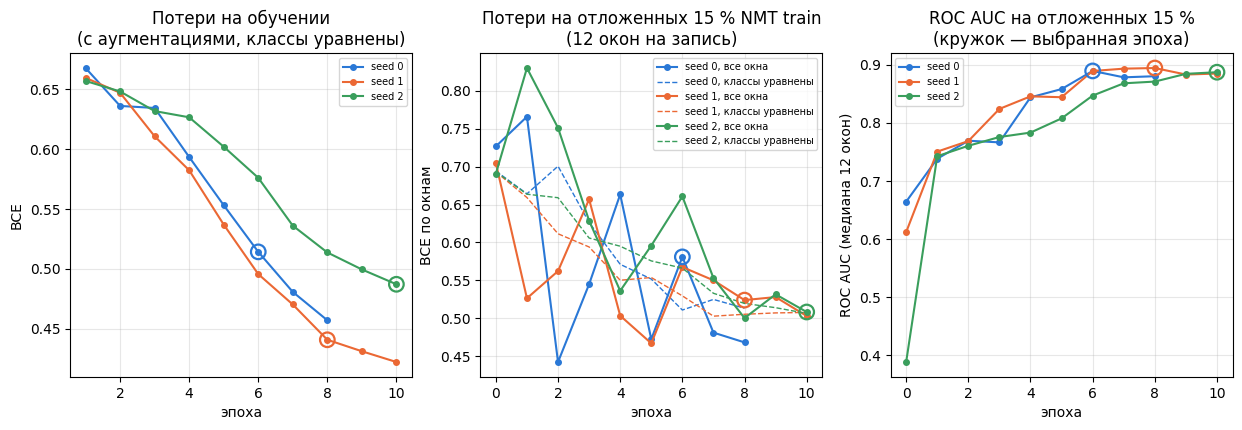

In [ ]:
# проверка: веса загружаются отдельным модулем eegdino_v2_model.py и дают те же вероятности
import importlib, sys as _sys
_sys.path.insert(0, OUT); dm = importlib.import_module("eegdino_v2_model")
ck = torch.load(f"{OUT}/eegdino_v2_seed0.pt", map_location="cpu", weights_only=False)
m = dm.DinoNet(); m.load_state_dict(ck["state_dict"]); m = m.to(DEV).eval()
W0 = windows(REC[val.id[0]], L)[:8]
with torch.no_grad(), torch.autocast(**AMP):
    p_file = torch.sigmoid(m(dm.dino_input(W0).to(DEV)).float()).cpu().numpy()
print("загрузка из файла: макс. расхождение вероятностей", float(np.abs(p_file - RUNS[0]["P"]["nmt_val"][0][:8]).max()), "| конфиг:", {k: ck["config"][k] for k in ["seed", "best_epoch", "val_auc_12win_median"]})
assert np.allclose(p_file, RUNS[0]["P"]["nmt_val"][0][:8], atol=1e-2)
del m, ck

CV = pd.DataFrame(CURVES)
best = {r["seed"]: r["best_ep"] for r in RUNS}
CV["best"] = (CV.epoch == CV.seed.map(best)).astype(int)
CV.round(4).to_csv(f"{OUT}/eegdino_v2_curves.csv", index=False)
print(CV.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
COL = {0: "#2a78d6", 1: "#eb6834", 2: "#3a9e5c"}
for s, g in CV.groupby("seed"):
    c, b = COL[s], g[g.best == 1]
    ax[0].plot(g.epoch, g.train_loss, "-o", color=c, ms=4, label=f"seed {s}")
    ax[1].plot(g.epoch, g.val_loss, "-o", color=c, ms=4, label=f"seed {s}, все окна")
    ax[1].plot(g.epoch, g.val_loss_bal, "--", color=c, lw=1, label=f"seed {s}, классы уравнены")
    ax[2].plot(g.epoch, g.val_auc, "-o", color=c, ms=4, label=f"seed {s}")
    for a_, col in [(ax[0], "train_loss"), (ax[1], "val_loss"), (ax[2], "val_auc")]:
        a_.scatter(b.epoch, b[col], s=110, facecolors="none", edgecolors=c, lw=1.6, zorder=3)
ax[0].set(xlabel="эпоха", ylabel="BCE", title="Потери на обучении\n(с аугментациями, классы уравнены)")
ax[1].set(xlabel="эпоха", ylabel="BCE по окнам", title="Потери на отложенных 15 % NMT train\n(12 окон на запись)")
ax[2].set(xlabel="эпоха", ylabel="ROC AUC (медиана 12 окон)", title="ROC AUC на отложенных 15 %\n(кружок — выбранная эпоха)")
for a_ in ax: a_.legend(fontsize=7); a_.grid(alpha=.3)
save_png(fig, "eegdino_v2_curves.png")

top20 = lambda p: np.sort(p)[::-1][:int(np.ceil(0.2 * len(p)))].mean()
AGGS = {"верхние 20 %": top20, "медиана": np.median}
VIEWS = {"60 окон": lambda p: p[spread(len(p), CAP_EVAL)], "все окна": lambda p: p}
def fmt(y, s):
    lo, hi = boot_ci(y, s); return f"{roc_auc_score(y, s):.3f} ({lo:.2f}–{hi:.2f})"
sd = lambda v: v.std(ddof=1) if len(v) > 1 else 0.0
S = {(v, a): {ds: np.array([[f(vf(p)) for p in r["P"][ds]] for r in RUNS]) for ds in SETS} for v, vf in VIEWS.items() for a, f in AGGS.items()}
srows, parts = [], []
for (v, a), D in S.items():
    prob = {ds: D[ds].mean(0) for ds in SETS}
    per_run = {ds: np.array([roc_auc_score(SETS[ds].y, s) for s in D[ds]]) for ds in SETS}
    srows.append({"окна": v, "сборка": a, **{f"{LAB[ds]}, ансамбль": fmt(SETS[ds].y.to_numpy(), prob[ds]) for ds in SETS},
                  **{f"{LAB[ds]}, запуски": f"{per_run[ds].mean():.3f} ± {sd(per_run[ds]):.3f} ({' / '.join(f'{x:.2f}' for x in per_run[ds])})" for ds in SETS}})
    for ds, d in SETS.items():
        t = pd.DataFrame({"dataset": ds, "id": d.id, "y": d.y, "окна": v, "сборка": a})
        for r, s in zip(RUNS, D[ds]): t[f"dino2_seed{r['seed']}"] = s
        t["dino2_ens_prob"] = prob[ds]
        parts.append(t)
summary = pd.DataFrame(srows); summary.to_csv(f"{OUT}/eegdino_v2_summary.csv", index=False)
print(summary.T.to_string())
PPD = pd.concat(parts, ignore_index=True); PPD.to_csv(f"{OUT}/eegdino_v2_per_person_all_views.csv", index=False)

runs = pd.DataFrame([{**{k: v for k, v in r.items() if k != "P"},
                      **{f"{ds}_{v}_{a}": round(roc_auc_score(SETS[ds].y, S[(v, a)][ds][j]), 4) for (v, a) in S for ds in SETS}}
                     for j, r in enumerate(RUNS)])
runs.to_csv(f"{OUT}/eegdino_v2_runs.csv", index=False)
print(runs[["seed", "best_ep", "n_ep", "stop", "best_auc", "n_bad", "minutes", "min_per_ep"]].to_string(index=False))

wparts = []
for ds, d in SETS.items():
    for r in RUNS:
        P = r["P"][ds]; n = [len(p) for p in P]
        in60 = np.concatenate([np.isin(np.arange(k), spread(k, CAP_EVAL)) for k in n])
        wparts.append(pd.DataFrame({"dataset": ds, "id": np.repeat(d.id.to_numpy(), n), "y": np.repeat(d.y.to_numpy(), n),
                                    "window": np.concatenate([np.arange(k) for k in n]), "in60": in60.astype(int), "seed": r["seed"], "p": np.concatenate(P).round(6)}))
pd.concat(wparts).to_csv(f"{OUT}/eegdino_v2_window_scores.csv.gz", index=False, compression="gzip")
print(f"осталось {left():.0f} мин")

## 5. Сравнение со старой EEG-DINO и REVE v4, ансамбль REVE v4 + EEG-DINO v2, пороги, калибровка, подгруппы EpiEEG-60
Оценки других моделей — из выходов ядер: REVE v4 — `h1-reve-v4` (`reve_v4_per_person.csv`) и `h1-epieeg60-reve` (`epieeg60_per_person.csv`, там же число пометок разрядов `n_ied_marks`); старая EEG-DINO — `h1-eegdino-finetune` (seed 0, 1) и `h1-eegdino-seed2` (seed 2), медиана 60 окон. Основной вид — 60 окон, среднее верхних 20 %, ансамбль запусков — среднее вероятностей.

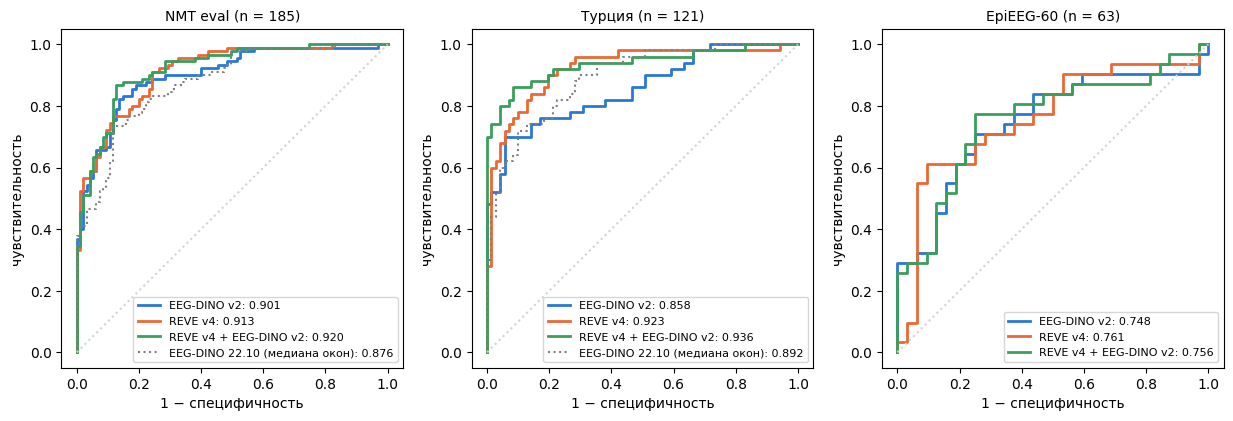

In [ ]:
def find(name):
    hits = sorted(glob.glob(f"/kaggle/input/**/{name}", recursive=True)); assert hits, name; return hits[0]
MAIN = ("60 окон", "верхние 20 %")
R4 = pd.read_csv(find("reve_v4_per_person.csv"))
R4 = R4[(R4["окна"] == MAIN[0]) & (R4["сборка"] == MAIN[1])][["dataset", "id", "y", "reve4_ens_prob"]]
E4 = pd.read_csv(find("epieeg60_per_person.csv"))
E4 = E4[(E4["окна"] == MAIN[0]) & (E4["сборка"] == MAIN[1])].rename(columns={"person": "id"}).assign(dataset="epieeg60")[["dataset", "id", "y", "reve4_ens_prob", "n_ied_marks"]]
OLD = pd.read_csv(find("eegdino_finetune_per_person.csv")).drop(columns=["eegdino_seed2", "eegdino_ens_rank", "amp"], errors="ignore")
OLD = OLD.merge(pd.read_csv(find("eegdino_seed2_per_person.csv")), on=["dataset", "id"], suffixes=("", "_s2"))
assert (OLD.y == OLD.y_s2).all()
OLD["dino_old_prob"] = OLD[["eegdino_seed0", "eegdino_seed1", "eegdino_seed2"]].mean(1)

def dino_view(v, a):
    return PPD[(PPD["окна"] == v) & (PPD["сборка"] == a)][["dataset", "id", "y", "dino2_ens_prob"]]
M = dino_view(*MAIN).merge(dino_view("60 окон", "медиана").rename(columns={"dino2_ens_prob": "dino2_med_prob"}), on=["dataset", "id", "y"])
M = M.merge(pd.concat([R4, E4[["dataset", "id", "y", "reve4_ens_prob"]]]), on=["dataset", "id"], how="left", suffixes=("", "_r"))
M = M.merge(OLD[["dataset", "id", "y", "dino_old_prob"]], on=["dataset", "id"], how="left", suffixes=("", "_o"))
M = M.merge(E4[["id", "n_ied_marks"]], on="id", how="left")
assert M.reve4_ens_prob.notna().all() and (M.y == M.y_r).all(), "оценки REVE v4 найдены не для всех"
assert M[M.dataset != "epieeg60"].dino_old_prob.notna().all() and (M.y_o.isna() | (M.y == M.y_o)).all()
M = M.drop(columns=["y_r", "y_o"])
M["ens_reve4_dino2"] = (M.reve4_ens_prob + M.dino2_ens_prob) / 2
M["ens_reve4_dino_old"] = (M.reve4_ens_prob + M.dino_old_prob) / 2
M.to_csv(f"{OUT}/eegdino_v2_per_person.csv", index=False)
print({ds: int((M.dataset == ds).sum()) for ds in SETS}, "человек с оценками всех моделей")

NAME = {"dino2_ens_prob": "EEG-DINO v2", "dino2_med_prob": "EEG-DINO v2 (медиана окон)", "dino_old_prob": "EEG-DINO 22.10 (медиана окон)",
        "reve4_ens_prob": "REVE v4", "ens_reve4_dino2": "REVE v4 + EEG-DINO v2", "ens_reve4_dino_old": "REVE v4 + EEG-DINO 22.10"}
G = {ds: M[M.dataset == ds].reset_index(drop=True) for ds in SETS}

# ROC AUC всех моделей
rows = []
for c, n in NAME.items():
    row = {"модель": n}
    for ds in SETS:
        d = G[ds]
        row[LAB[ds]] = fmt(d.y.to_numpy(), d[c].to_numpy()) if d[c].notna().all() else "нет"
    rows.append(row)
AUCT = pd.DataFrame(rows); AUCT.to_csv(f"{OUT}/eegdino_v2_auc_compare.csv", index=False)
pd.set_option("display.width", 250, "display.max_colwidth", 80)
print(AUCT.to_string(index=False))

# парные разности ROC AUC, бутстреп по людям
def paired(y, s1, s2, n=2000, seed=0):
    r = np.random.default_rng(seed); v = []
    for _ in range(n):
        i = r.integers(0, len(y), len(y))
        if len(set(y[i])) == 2: v.append(roc_auc_score(y[i], s1[i]) - roc_auc_score(y[i], s2[i]))
    return roc_auc_score(y, s1) - roc_auc_score(y, s2), np.percentile(v, [2.5, 97.5])
PAIRS = [("dino2_ens_prob", "dino_old_prob", "сборки разные: v2 — верхние 20 %, 22.10 — медиана"),
         ("dino2_med_prob", "dino_old_prob", "одна сборка (медиана 60 окон): эффект обучения"),
         ("ens_reve4_dino2", "reve4_ens_prob", ""), ("dino2_ens_prob", "reve4_ens_prob", ""),
         ("ens_reve4_dino2", "ens_reve4_dino_old", "")]
DR = []
for a, b, note in PAIRS:
    for ds in ["nmt_eval", "turkey", "epieeg60"]:
        d = G[ds]
        if d[a].isna().any() or d[b].isna().any():
            DR.append(dict(разность=f"{NAME[a]} − {NAME[b]}", набор=LAB[ds], n=len(d), ΔROC_AUC=np.nan, ДИ="нет: старой EEG-DINO на EpiEEG-60 нет", примечание=note)); continue
        dv, (lo, hi) = paired(d.y.to_numpy(), d[a].to_numpy(), d[b].to_numpy())
        DR.append(dict(разность=f"{NAME[a]} − {NAME[b]}", набор=LAB[ds], n=len(d), ΔROC_AUC=round(dv, 3), ДИ=f"{lo:+.3f}…{hi:+.3f}", примечание=note))
DR = pd.DataFrame(DR); DR.to_csv(f"{OUT}/eegdino_v2_paired_differences.csv", index=False)
print(DR.to_string(index=False))

# пороговые метрики: порог по отложенным 15 % NMT train (Юден, чувствительность 80 %), на остальные наборы — без изменений
def metr(y, pr):
    tp, tn = ((pr == 1) & (y == 1)).sum(), ((pr == 0) & (y == 0)).sum(); fp, fn = ((pr == 1) & (y == 0)).sum(), ((pr == 0) & (y == 1)).sum()
    rec = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1)
    return dict(acc=(tp + tn) / len(y), bacc=(rec + spec) / 2, prec=tp / (tp + fp) if tp + fp else np.nan, rec=rec, spec=spec)
def metr_ci(y, s, t, n=2000, seed=0):
    pr = (s >= t).astype(int); m0 = metr(y, pr); r = np.random.default_rng(seed); B = []
    for _ in range(n):
        i = r.integers(0, len(y), len(y)); B.append(metr(y[i], pr[i]))
    return {k: f"{m0[k]:.2f} ({np.nanpercentile([b[k] for b in B], 2.5):.2f}–{np.nanpercentile([b[k] for b in B], 97.5):.2f})" for k in m0}
def thr_youden(y, s):
    f, t, th = roc_curve(y, s); return float(th[np.argmax(t - f)])
def thr_sens(y, s, target=0.8):
    f, t, th = roc_curve(y, s); return float(th[np.where(t >= target)[0][0]])
RULES = {"Юден": thr_youden, "чувствительность 80 %": thr_sens}
THR = {(c, rn): f(G["nmt_val"].y.to_numpy(), G["nmt_val"][c].to_numpy()) for c in ["dino2_ens_prob", "reve4_ens_prob", "ens_reve4_dino2"] for rn, f in RULES.items()}
TR = []
for (c, rn), t in THR.items():
    for ds in SETS:
        d = G[ds]; y, s = d.y.to_numpy(), d[c].to_numpy(); mm = metr_ci(y, s, t)
        TR.append({"модель": NAME[c], "порог": rn, "значение порога": round(t, 3), "набор": LAB[ds], "n": len(y), "ROC AUC": fmt(y, s),
                   "accuracy": mm["acc"], "сбаланс. accuracy": mm["bacc"], "precision": mm["prec"], "recall (чувств.)": mm["rec"], "специфичность": mm["spec"],
                   "примечание": "порог: отложенные 15 % NMT train" + ("" if ds == "nmt_val" else "; перенесён без изменений")})
TR = pd.DataFrame(TR); TR.to_csv(f"{OUT}/eegdino_v2_threshold_metrics.csv", index=False)
print(TR.drop(columns=["примечание"]).to_string(index=False))

# калибровка на месте: порог по k случайным людям набора, метрики на остальных; 500 повторов, одни и те же выборки для всех моделей
CAL_M = {"turkey": ["dino2_ens_prob", "dino_old_prob", "reve4_ens_prob", "ens_reve4_dino2", "ens_reve4_dino_old"],
         "epieeg60": ["dino2_ens_prob", "reve4_ens_prob", "ens_reve4_dino2"]}
CR = []
for ds, cols in CAL_M.items():
    d = G[ds]; y = d.y.to_numpy()
    for k in [10, 20]:
        if k > len(d) - 4: continue
        rng = np.random.default_rng(0)
        for rep in range(500):
            idx = rng.permutation(len(d)); cal, test = idx[:k], idx[k:]
            if len(set(y[cal])) < 2: continue
            for c in cols:
                s = d[c].to_numpy()
                for rn, f in [("Юден", thr_youden), ("recall 80 %", thr_sens)]:
                    th = f(y[cal], s[cal])
                    CR.append(dict(набор=LAB[ds], калибровка=f"{k} чел.", модель=NAME[c], порог=rn, **metr(y[test], (s[test] >= th).astype(int))))
CR = pd.DataFrame(CR); key = ["набор", "калибровка", "модель", "порог"]
g = CR.groupby(key, sort=False)
CAL = (g.mean().round(2).astype(str) + " (" + g.quantile(.025).round(2).astype(str) + "–" + g.quantile(.975).round(2).astype(str) + ")")
CAL = CAL.rename(columns={"acc": "accuracy", "bacc": "сбаланс. accuracy", "prec": "precision", "rec": "recall", "spec": "специфичность"}).reset_index()
CAL.insert(4, "повторов", g.size().values)
CAL.to_csv(f"{OUT}/eegdino_v2_local_threshold_calibration.csv", index=False)
print(CAL.to_string(index=False))

# EpiEEG-60: больные с размеченными разрядами и без — каждая подгруппа против всех здоровых
d = G["epieeg60"]; SUB = []
for name, q in [("все", d), ("больные с пометками разрядов", d[(d.y == 0) | (d.n_ied_marks > 0)]),
                ("больные без пометок разрядов", d[(d.y == 0) | (d.n_ied_marks == 0)]),
                ("все больные; здоровые без пометок", d[(d.y == 1) | (d.n_ied_marks == 0)])]:
    y = q.y.to_numpy()
    if len(set(y)) < 2: continue
    for c in ["dino2_ens_prob", "reve4_ens_prob", "ens_reve4_dino2"]:
        s = q[c].to_numpy(); t = THR[(c, "Юден")]
        row = dict(подгруппа=name, модель=NAME[c], n_норма=int((y == 0).sum()), n_эпилепсия=int(y.sum()), ROC_AUC=fmt(y, s),
                   recall_при_пороге_NMT=round(float((s[y == 1] >= t).mean()), 2), специфичность_при_пороге_NMT=round(float((s[y == 0] < t).mean()), 2),
                   медиана_оценки_больных=round(float(np.median(s[y == 1])), 3))
        if c != "reve4_ens_prob":
            dv, (lo, hi) = paired(y, s, q.reve4_ens_prob.to_numpy()); row["Δ к REVE v4"] = f"{dv:+.3f} ({lo:+.3f}…{hi:+.3f})"
        SUB.append(row)
SUB = pd.DataFrame(SUB); SUB.to_csv(f"{OUT}/eegdino_v2_epieeg60_subgroups.csv", index=False)
print(SUB.to_string(index=False))

# ROC: EEG-DINO v2, REVE v4 и их ансамбль на трёх наборах
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
for a_, ds in zip(ax, ["nmt_eval", "turkey", "epieeg60"]):
    dd = G[ds]; y = dd.y.to_numpy()
    for c, col in [("dino2_ens_prob", "#2a78d6"), ("reve4_ens_prob", "#eb6834"), ("ens_reve4_dino2", "#3a9e5c")]:
        f_, t_, _ = roc_curve(y, dd[c]); a_.plot(f_, t_, color=col, lw=2, label=f"{NAME[c]}: {roc_auc_score(y, dd[c]):.3f}")
    if dd.dino_old_prob.notna().all():
        f_, t_, _ = roc_curve(y, dd.dino_old_prob); a_.plot(f_, t_, ":", color="gray", lw=1.5, label=f"{NAME['dino_old_prob']}: {roc_auc_score(y, dd.dino_old_prob):.3f}")
    a_.plot([0, 1], [0, 1], ":", color="lightgray")
    a_.set(xlabel="1 − специфичность", ylabel="чувствительность", title=f"{LAB[ds]} (n = {len(y)})"); a_.legend(fontsize=8, loc="lower right")
save_png(fig, "eegdino_v2_roc.png")
print("файлы:", sorted(os.listdir(OUT)), sorted(os.listdir(FIG)))
print(f"\nвсё время блокнота: {(time.time()-T_NB)/60:.1f} мин")

## Вывод блокнота на Kaggle

Блокнот выполнен на Kaggle (`zakharsann/h1-eegdino-v2`, версия 1, T4). Kaggle CLI не отдаёт выполненный `__notebook__.ipynb`, поэтому вывод ячеек собран ниже из журнала ядра одним блоком; картинки вставлены в ячейки, где они строятся.

In [ ]:
# вывод выполнения на Kaggle (журнал ядра, stdout)

EEG-DINO-M: кодировщик 227 тензоров загружено строго; параметров 34445121
устройство: Tesla T4 | ядер процессора: 4
общий набор: /kaggle/input/notebooks/zakharsann/h1-prep-shared {'fs': [200], 'nmt_scale_k': 100.0, 'nmt_train_cap_min': None, 'size_gb': 14.56}
прочитано 2598 записей за 35 с, ФВЧ 0,3 Гц 87 с | 15.6 ГБ | осталось 128 мин
y          0    1
split            
eval      95   90
fit     1618  276
turkey    71   50
val      286   49
EpiEEG-60, людей: {0: 32, 1: 31} | записей: 63
окон подряд: nmt_val 23525, nmt_eval 13118, turkey 15505, epieeg60 13447 | для выбора эпохи: 4001
записей fit: 1894 (патология 0.15), окон за эпоху: 15152
  запуск 0 | эпоха 1: потери обуч. 0.668 | отложенные: потери 0.766 (уравн. 0.664), ROC AUC 0.738 | NaN/inf 0 | 134 с | осталось 125 мин
  запуск 0 | эпоха 2: потери обуч. 0.636 | отложенные: потери 0.442 (уравн. 0.701), ROC AUC 0.769 | NaN/inf 0 | 267 с | осталось 123 мин
  запуск 0 | эпоха 3: потери обуч. 0.634 | отложенные: потери 0.545 (уравн. 0.6